# Delivery performance and customer reviews — exploration and metric validation

**Project:** Improving E-Commerce Delivery Performance and Customer Reviews (Olist, Brazil, 2016–2018)

This notebook has two jobs:

1. **Independently validate** the headline SQL metrics. Every number here is recomputed with pandas
   directly from the raw CSVs in `data/raw/` and compared with the SQLite analytics model (`data/processed/olist.db`) built by
   `scripts/build_database.py`. Any mismatch raises an `AssertionError`.
2. **Explore** the questions the SQL tables can't show well: trends, distributions, the review-score
   gap, whether rankings are driven by small groups, and whether findings survive robustness checks.

It deliberately does not repeat every dashboard chart.

**Grain reminders**
- *Order* = one row in `olist_orders_dataset.csv` (99,441). Late rate, review score and lifecycle times are order-grain.
- *Order item* = one row in `olist_order_items_dataset.csv` (112,650). Never count orders from it without de-duplicating.
- Delivery KPIs use orders with status `delivered` **and** a customer delivery timestamp (96,470 orders).
- **Late** = delivered on a later *calendar date* than the estimated delivery date (the estimate has no time of day).

Run `python scripts/build_database.py` first.

In [1]:
from pathlib import Path
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
# Read-only connection to the SQLite database built by scripts/build_database.py
con = sqlite3.connect(f"file:{(ROOT / 'data' / 'processed' / 'olist.db').as_posix()}?mode=ro", uri=True)
sql = lambda q: pd.read_sql_query(q, con)

# SQLite stores flags as 1/0 (NULL = not applicable) and dates as ISO text.
FLAG_PREFIXES = ("is_", "has_")
FLAG_COLUMNS = {"in_trend_window", "used_voucher", "review_has_comment", "review_created_before_delivery"}

def typed(df):
    # Convert SQLite 1/0 flags to nullable booleans and ISO dates to datetimes.
    for c in df.columns:
        if c.startswith(FLAG_PREFIXES) or c in FLAG_COLUMNS:
            df[c] = df[c].astype("boolean")
        elif c in ("purchase_date", "purchase_month"):
            df[c] = pd.to_datetime(df[c])
    return df

# Chart style: one palette for the whole project (also used in Power BI theme).
ON_TIME, LATE, NEUTRAL = "#2a78d6", "#eb6834", "#8a8984"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "semibold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.titlecolor": INK,
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Load raw CSVs (pandas, independent of SQL) and confirm table grain

In [2]:
parse = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
         "order_delivered_customer_date", "order_estimated_delivery_date"]
orders   = pd.read_csv(RAW / "olist_orders_dataset.csv", parse_dates=parse)
items    = pd.read_csv(RAW / "olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
reviews  = pd.read_csv(RAW / "olist_order_reviews_dataset.csv", parse_dates=["review_creation_date", "review_answer_timestamp"])
payments = pd.read_csv(RAW / "olist_order_payments_dataset.csv")
customers= pd.read_csv(RAW / "olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
sellers  = pd.read_csv(RAW / "olist_sellers_dataset.csv", dtype={"seller_zip_code_prefix": str})
products = pd.read_csv(RAW / "olist_products_dataset.csv")
transl   = pd.read_csv(RAW / "product_category_name_translation.csv")

grain = pd.DataFrame({
    "table": ["orders", "order_items", "order_payments", "order_reviews", "customers", "sellers", "products"],
    "rows": [len(orders), len(items), len(payments), len(reviews), len(customers), len(sellers), len(products)],
    "candidate_key": ["order_id", "order_id+order_item_id", "order_id+payment_sequential", "review_id+order_id",
                      "customer_id", "seller_id", "product_id"],
    "key_is_unique": [orders.order_id.is_unique,
                      not items.duplicated(["order_id", "order_item_id"]).any(),
                      not payments.duplicated(["order_id", "payment_sequential"]).any(),
                      not reviews.duplicated(["review_id", "order_id"]).any(),
                      customers.customer_id.is_unique, sellers.seller_id.is_unique, products.product_id.is_unique],
})
assert grain.key_is_unique.all()
grain

,table,rows,candidate_key,key_is_unique
0,orders,99441,order_id,True
1,order_items,112650,order_id+order_item_id,True
2,order_payments,103886,order_id+payment_sequential,True
3,order_reviews,99224,review_id+order_id,True
4,customers,99441,customer_id,True
5,sellers,3095,seller_id,True
6,products,32951,product_id,True


**Join-cardinality check.** Joining orders to items is one-to-many. A naive join inflates the order count,
and that's exactly the double counting the model avoids by aggregating items to order grain first.

In [3]:
naive = orders.merge(items, on="order_id", how="left")
print(f"orders: {len(orders):,}  ->  rows after naive orders x items join: {len(naive):,} "
      f"(+{len(naive) - len(orders):,} duplicated order rows)")
print(f"orders with more than one item: {(items.groupby('order_id').size() > 1).sum():,}")

# Safe pattern: aggregate to order grain, then join (row count must not change)
items_per_order = items.groupby("order_id").agg(item_count=("order_item_id", "size"),
                                                order_value_brl=("price", "sum"),
                                                freight_brl=("freight_value", "sum"))
safe = orders.merge(items_per_order, on="order_id", how="left", validate="one_to_one")
assert len(safe) == len(orders)
print(f"rows after aggregate-then-join: {len(safe):,}  (unchanged)")

orders: 99,441  ->  rows after naive orders x items join: 113,425 (+13,984 duplicated order rows)
orders with more than one item: 9,803


rows after aggregate-then-join: 99,441  (unchanged)


## 2. Independent recomputation of the headline metrics vs. SQL

In [4]:
o = orders.copy()
o["eligible"] = (o.order_status == "delivered") & o.order_delivered_customer_date.notna()
d = o[o.eligible].copy()
d["is_late"] = d.order_delivered_customer_date.dt.normalize() > d.order_estimated_delivery_date.dt.normalize()
d["is_late_ts"] = d.order_delivered_customer_date > d.order_estimated_delivery_date

# One review per order: most recently answered (same rule as stg_order_review)
rev1 = (reviews.sort_values(["order_id", "review_answer_timestamp", "review_creation_date", "review_id"],
                            ascending=[True, False, False, True])
               .drop_duplicates("order_id"))
d = d.merge(rev1[["order_id", "review_score", "review_creation_date"]], on="order_id", how="left",
            validate="one_to_one")

py = {
    "delivered_orders (denominator)": len(d),
    "late_orders (calendar-date rule)": int(d.is_late.sum()),
    "late_pct (calendar-date rule)": round(100 * d.is_late.mean(), 2),
    "late_pct (timestamp rule)": round(100 * d.is_late_ts.mean(), 2),
    "avg_review_on_time": round(d.loc[~d.is_late, "review_score"].mean(), 3),
    "avg_review_late": round(d.loc[d.is_late, "review_score"].mean(), 3),
    "reviewed_late_orders": int(d.loc[d.is_late, "review_score"].notna().sum()),
    "canceled_or_unavailable_pct": round(100 * orders.order_status.isin(["canceled", "unavailable"]).mean(), 2),
}
s = sql("""
SELECT COUNT(*) FILTER (WHERE is_delivery_kpi_eligible)                          AS a,
       COUNT(*) FILTER (WHERE is_late)                                           AS b,
       ROUND(100.0 * AVG(is_late), 2)                                       AS c,
       ROUND(100.0 * AVG(is_late_timestamp_rule), 2)                        AS d,
       ROUND(AVG(review_score) FILTER (WHERE NOT is_late), 3)                    AS e,
       ROUND(AVG(review_score) FILTER (WHERE is_late), 3)                        AS f,
       COUNT(review_score) FILTER (WHERE is_late)                                AS g,
       ROUND(100.0 * AVG((order_status IN ('canceled','unavailable'))), 2)  AS h
FROM fct_orders""").iloc[0].tolist()
check = pd.DataFrame({"metric": list(py), "pandas_from_raw_csv": list(py.values()), "sqlite_sql_model": s})
check["match"] = np.isclose(check.pandas_from_raw_csv.astype(float), check.sqlite_sql_model.astype(float))
assert check.match.all(), check
check

,metric,pandas_from_raw_csv,sqlite_sql_model,match
0,delivered_orders (denominator),"96,470.000","96,470.000",True
1,late_orders (calendar-date rule),"6,534.000","6,534.000",True
2,late_pct (calendar-date rule),6.770,6.770,True
3,late_pct (timestamp rule),8.110,8.110,True
4,avg_review_on_time,4.290,4.290,True
5,avg_review_late,2.270,2.270,True
6,reviewed_late_orders,"6,381.000","6,381.000",True
7,canceled_or_unavailable_pct,1.240,1.240,True


In [5]:
# Lifecycle medians: recompute with the same validity rules (both timestamps present and in order)
def stage(a, b, unit=86400):
    ok = d[b].notna() & d[a].notna() & (d[b] >= d[a])
    return (d.loc[ok, b] - d.loc[ok, a]).dt.total_seconds() / unit

py_stage = {
    "purchase -> approval (hours)": stage("order_purchase_timestamp", "order_approved_at", 3600).median(),
    "approval -> carrier (days)": stage("order_approved_at", "order_delivered_carrier_date").median(),
    "carrier -> customer (days)": stage("order_delivered_carrier_date", "order_delivered_customer_date").median(),
}
# SQLite has no MEDIAN(): the SQL computes it with window functions (sql/05_headline_metrics.sql).
# Compare those SQL medians with pandas medians recomputed from the raw CSVs.
headline = json.loads((ROOT / "reports" / "headline_metrics.json").read_text())["metrics"]
sql_stage = [headline["median_hours_purchase_to_approval"], headline["median_days_approval_to_carrier"],
             headline["median_days_carrier_to_customer"]]
stage_check = pd.DataFrame({"stage": list(py_stage), "pandas": list(py_stage.values()), "sql": sql_stage})
stage_check["match"] = np.isclose(stage_check.pandas, stage_check.sql)
assert stage_check.match.all()
stage_check

,stage,pandas,sql,match
0,purchase -> approval (hours),0.343,0.343,True
1,approval -> carrier (days),1.849,1.849,True
2,carrier -> customer (days),7.100,7.100,True


All headline metrics match to the reported precision. From here on the notebook reads the validated
analytics model (`fct_orders`, order grain) to keep the code short.

In [6]:
f = typed(sql("SELECT * FROM fct_orders"))
dl = f[f.is_delivery_kpi_eligible].copy()          # delivery-KPI population (order grain)
market_rate = dl.is_late.mean()
print(f"Delivered orders: {len(dl):,} | late: {dl.is_late.sum():,} | late rate: {market_rate:.2%}")

Delivered orders: 96,470 | late: 6,534 | late rate: 6.77%


## 3. Order volume and late-delivery trend

Two panels with a shared time axis instead of one dual-axis chart. Purchase month, complete months only (Jan-2017 to Aug-2018).

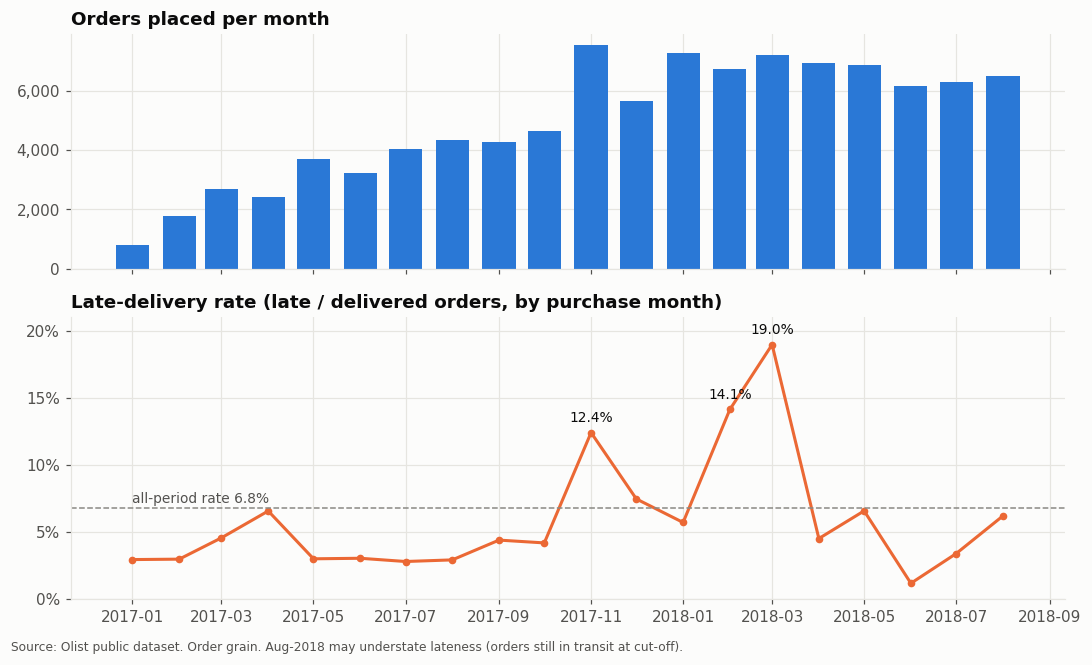

,orders,delivered,late,late_rate
purchase_month,,,,
2017-10-01,4631,4478,187,4.200
2017-11-01,7544,7288,904,12.400
2017-12-01,5673,5513,411,7.500
2018-01-01,7269,7069,403,5.700
2018-02-01,6728,6555,926,14.100
2018-03-01,7211,7003,1328,19.000
2018-04-01,6939,6798,306,4.500


In [7]:
m = (f[f.in_trend_window]
     .groupby("purchase_month")
     .agg(orders=("order_id", "size"),
          delivered=("is_delivery_kpi_eligible", "sum"),
          late=("is_late", lambda s: s.fillna(False).sum())))
m["late_rate"] = m.late / m.delivered

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
a1.bar(m.index, m.orders, width=22, color=ON_TIME)
a1.set_title("Orders placed per month")
a1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
a2.plot(m.index, m.late_rate, color=LATE, lw=2, marker="o", ms=4)
a2.axhline(market_rate, color=NEUTRAL, lw=1, ls="--")
a2.text(m.index[0], market_rate + 0.004, f"all-period rate {market_rate:.1%}", color=INK_2, fontsize=9)
for t in ["2017-11-01", "2018-02-01", "2018-03-01"]:
    t = pd.Timestamp(t); a2.annotate(f"{m.loc[t,'late_rate']:.1%}", (t, m.loc[t, "late_rate"]),
                                     xytext=(0, 7), textcoords="offset points", ha="center", color=INK, fontsize=9)
a2.set_title("Late-delivery rate (late / delivered orders, by purchase month)")
a2.yaxis.set_major_locator(mtick.MultipleLocator(0.05)); a2.set_ylim(0, 0.21)
a2.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
fig.text(0.01, 0.005, "Source: Olist public dataset. Order grain. Aug-2018 may understate lateness (orders still in transit at cut-off).",
         fontsize=8, color=INK_2)
fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig(FIG_DIR / "01_monthly_volume_and_late_rate.png", dpi=150)
plt.show()
m.assign(late_rate=lambda x: (100 * x.late_rate).round(1)).loc["2017-10-01":"2018-04-01"]

**Reading:** lateness isn't steady. It spikes in **Nov-2017** (Black Friday volume, 12.4%) and peaks in
**Feb–Mar 2018** (14.1% and 19.0%), then falls back to 1–7%. The spike months account for a large share of all late orders:

In [8]:
spike = dl.purchase_month.isin(pd.to_datetime(["2017-11-01", "2018-02-01", "2018-03-01"]))
print(f"Spike months: {spike.mean():.1%} of delivered orders but {dl.loc[spike, 'is_late'].sum() / dl.is_late.sum():.1%} of late orders")

# Is the Feb-Mar 2018 spike concentrated in one region, or broad-based?
reg = (dl.assign(period=np.where(dl.purchase_month.isin(pd.to_datetime(["2018-02-01", "2018-03-01"])),
                                 "Feb-Mar 2018", "all other months"))
         .pivot_table(index="customer_region", columns="period", values="is_late", aggfunc="mean"))
(100 * reg).round(1).sort_values("Feb-Mar 2018", ascending=False)

Spike months: 21.6% of delivered orders but 48.3% of late orders


period,Feb-Mar 2018,all other months
customer_region,,
North,27.400,5.900
Northeast,27.400,10.400
Center-West,18.400,4.400
South,15.900,4.200
Southeast,14.900,4.700


The Feb–Mar 2018 spike shows up in **every region**, so it's not a single-lane problem. That pattern points
to a marketplace-wide capacity or carrier disruption. The data can't confirm the cause because it has no
carrier identifier.

## 4. Review scores: on-time vs late

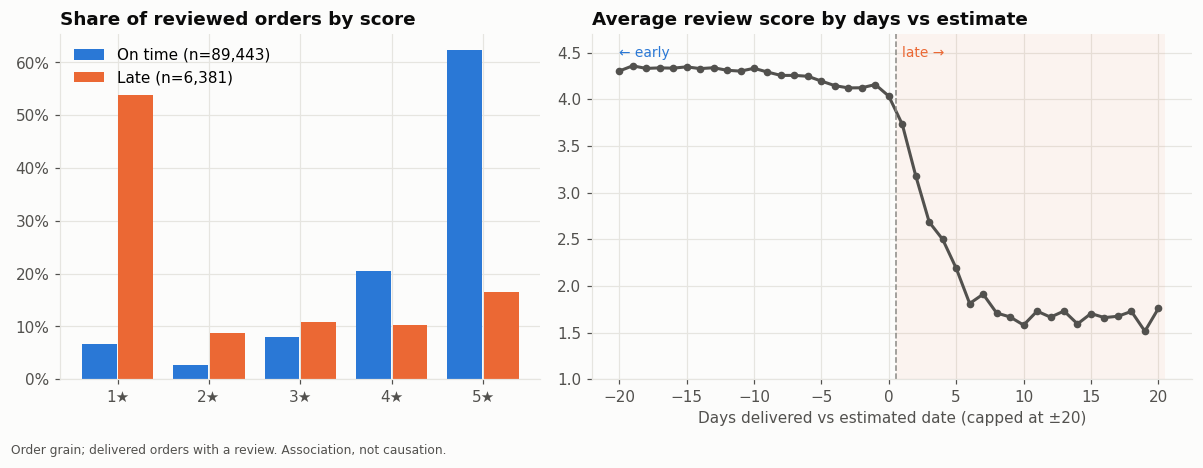

In [9]:
rv = dl[dl.review_score.notna()]
dist = (rv.groupby("is_late").review_score.value_counts(normalize=True).unstack().fillna(0))
n_by = rv.groupby("is_late").size()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
x = np.arange(1, 6); w = 0.38
a1.bar(x - w/2 - 0.01, dist.loc[False], w, color=ON_TIME, label=f"On time (n={n_by[False]:,})")
a1.bar(x + w/2 + 0.01, dist.loc[True],  w, color=LATE,    label=f"Late (n={n_by[True]:,})")
a1.set_xticks(x, [f"{i}★" for i in x]); a1.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
a1.set_title("Share of reviewed orders by score"); a1.legend(loc="upper left")

b = sql("""
SELECT MIN(MAX(days_vs_estimate, -20), 20) AS d, COUNT(review_score) AS n, AVG(review_score) AS avg_score
FROM fct_orders WHERE is_delivery_kpi_eligible GROUP BY 1 ORDER BY 1""")
a2.axvspan(0.5, 20.5, color=LATE, alpha=0.06, lw=0)
a2.plot(b.d, b.avg_score, color=INK_2, lw=2, marker="o", ms=4)
a2.axvline(0.5, color=NEUTRAL, lw=1, ls="--")
a2.text(1, 4.45, "late →", color=LATE, fontsize=9); a2.text(-20, 4.45, "← early", color=ON_TIME, fontsize=9)
a2.set_ylim(1, 4.7); a2.set_xlabel("Days delivered vs estimated date (capped at ±20)")
a2.set_title("Average review score by days vs estimate")
fig.text(0.01, 0.005, "Order grain; delivered orders with a review. Association, not causation.", fontsize=8, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(FIG_DIR / "02_reviews_on_time_vs_late.png", dpi=150)
plt.show()

**Reading:** late orders average **2.27 stars vs 4.29** (n = 6,381 vs 89,443 reviewed orders). 62% of reviews
on late orders are 1–2 stars, against 9% for on-time orders. The score is flat while orders arrive early and drops
sharply in the first week of lateness, then levels off around 1.7. That pattern fits delay *mattering* to
customers, but it is still an association.

### Robustness: is the gap driven by a subgroup or a data artefact?

In [10]:
top_sellers = (sql("""SELECT seller_id, COUNT(*) n FROM order_sellers os
                     JOIN fct_orders o USING (order_id) WHERE o.is_delivery_kpi_eligible
                     GROUP BY 1 ORDER BY n DESC LIMIT 10""").seller_id)
orders_top = set(sql("SELECT order_id, seller_id FROM order_sellers")
                 .query("seller_id in @top_sellers").order_id)

def gap(frame, label):
    r = frame[frame.review_score.notna()]
    on, lt = r.loc[~r.is_late, "review_score"], r.loc[r.is_late, "review_score"]
    return {"subset": label, "n_on_time": len(on), "n_late": len(lt),
            "mean_on_time": on.mean(), "mean_late": lt.mean(), "mean_gap": lt.mean() - on.mean(),
            "median_on_time": on.median(), "median_late": lt.median()}

rob = pd.DataFrame([
    gap(dl, "All delivered orders"),
    gap(dl[~dl.review_created_before_delivery.fillna(False).astype(bool)], "Only reviews written after delivery"),
    gap(dl[~spike], "Excluding spike months (Nov-17, Feb-18, Mar-18)"),
    gap(dl[~dl.order_id.isin(orders_top)], "Excluding the 10 largest sellers"),
    gap(dl[dl.customer_state != "SP"], "Excluding São Paulo customers"),
    gap(dl[dl.item_count == 1], "Single-item orders only"),
])
rob

,subset,n_on_time,n_late,mean_on_time,mean_late,mean_gap,median_on_time,median_late
0,All delivered orders,89443,6381,4.290,2.270,-2.020,5.000,1.000
1,Only reviews written after delivery,89218,1630,4.291,3.526,-0.765,5.000,4.000
2,"Excluding spike months (Nov-17, Feb-18, Mar-18)",71846,3286,4.308,2.470,-1.838,5.000,2.000
3,Excluding the 10 largest sellers,76827,5422,4.299,2.266,-2.033,5.000,1.000
4,Excluding São Paulo customers,50963,4595,4.265,2.163,-2.102,5.000,1.000
5,Single-item orders only,80407,5889,4.355,2.280,-2.075,5.000,1.000


In [11]:
before = dl[dl.is_late & dl.review_score.notna()].review_created_before_delivery.mean()
print(f"Late orders whose review was created BEFORE delivery: {before:.1%}")

Late orders whose review was created BEFORE delivery: 74.5%


**Reading:** the gap of about −2 points holds when spike months, the 10 largest sellers or São Paulo customers are excluded,
and in single-item orders (−1.84 to −2.10). It is not driven by one group or period.

There is one important caveat. **About 3 in 4 reviews on late orders were created before the parcel arrived.**
Olist appears to send the satisfaction survey around the estimated delivery date. Many late-order reviews
therefore rate a *missing* parcel rather than the product. Restricted to reviews written after delivery, the
gap shrinks to **−0.77 points** (3.53 vs 4.29, on only 1,630 late orders), and the median late score rises from 1 to 4.
Read the headline −2.0 as "late orders attract much worse reviews, *largely because many customers review an
order that has not arrived yet*." Two things follow: the delay itself is still associated with lower scores
after arrival, and survey timing amplifies the measured gap.

## 5. Sellers and categories: is the ranking driven by small samples?

A funnel plot shows each group's late rate against its volume, with 95% binomial limits around the
marketplace rate. Small sellers scatter widely by chance. Only points *above the upper limit* are
statistically unusual.

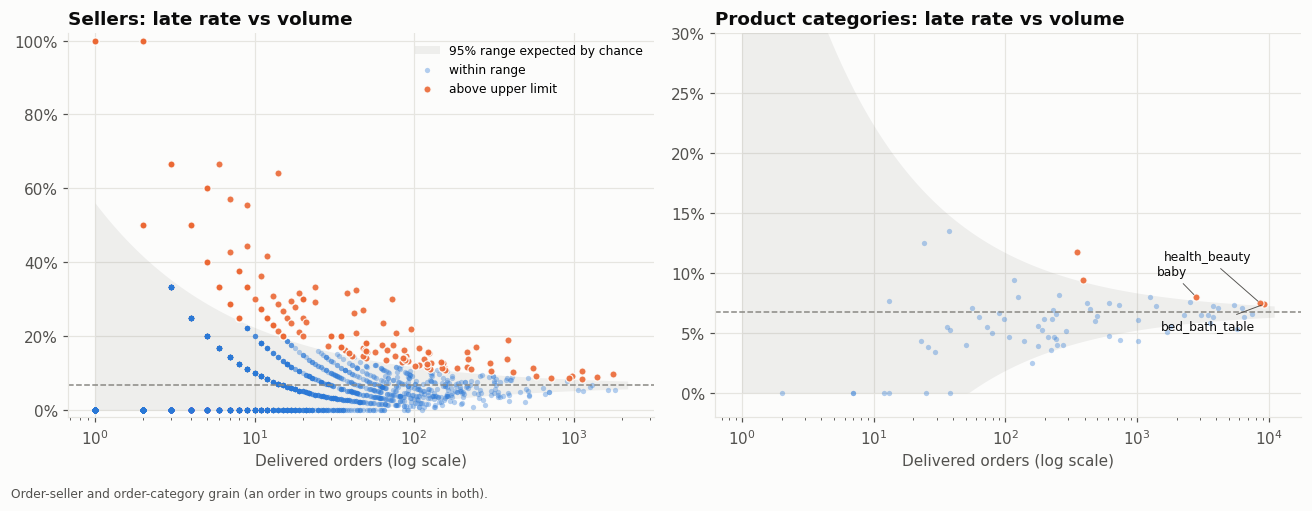

,sellers,categories
groups,2970,74
groups with < 30 orders,2343,11
above 95% upper limit,239,5
"above limit AND high volume (sellers>=100, categories>=500)",36,3


In [12]:
sel = sql("""
SELECT os.seller_id, COUNT(*) AS n, AVG(o.is_late) AS late_rate
FROM order_sellers os JOIN fct_orders o USING (order_id)
WHERE o.is_delivery_kpi_eligible GROUP BY 1""")
cat = sql("""
SELECT oc.category, COUNT(*) AS n, AVG(o.is_late) AS late_rate
FROM order_categories oc JOIN fct_orders o USING (order_id)
WHERE o.is_delivery_kpi_eligible GROUP BY 1""")

def limits(n, p=market_rate, z=1.96):
    se = np.sqrt(p * (1 - p) / n); return np.clip(p - z * se, 0, 1), p + z * se

sel["above_limit"] = sel.late_rate > limits(sel.n)[1]
cat["above_limit"] = cat.late_rate > limits(cat.n)[1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, df, title, ymax in [(axes[0], sel, "Sellers", 1.02), (axes[1], cat, "Product categories", 0.30)]:
    nn = np.logspace(0, np.log10(df.n.max() * 1.2), 200); lo, hi = limits(nn)
    ax.fill_between(nn, lo, hi, color=NEUTRAL, alpha=0.12, lw=0, label="95% range expected by chance")
    ax.axhline(market_rate, color=NEUTRAL, lw=1, ls="--")
    norm = df[~df.above_limit]; out = df[df.above_limit]
    ax.scatter(norm.n, norm.late_rate, s=12, color=ON_TIME, alpha=0.35, lw=0, label="within range")
    ax.scatter(out.n, out.late_rate, s=22, color=LATE, alpha=0.9, edgecolor=SURFACE, lw=0.8, label="above upper limit")
    ax.set_xscale("log"); ax.set_ylim(-0.02, ymax)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_xlabel("Delivered orders (log scale)"); ax.set_title(f"{title}: late rate vs volume")
axes[0].legend(loc="upper right", fontsize=8)
for (_, r), dy in zip(cat[cat.above_limit & (cat.n >= 500)].sort_values("n").iterrows(), [14, 28, -16]):
    axes[1].annotate(r.category, (r.n, r.late_rate), xytext=(-6, dy), textcoords="offset points", fontsize=8,
                     color=INK, ha="right", arrowprops={"arrowstyle": "-", "color": INK_2, "lw": 0.6})
fig.text(0.01, 0.005, "Order-seller and order-category grain (an order in two groups counts in both).", fontsize=8, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(FIG_DIR / "03_funnel_sellers_categories.png", dpi=150)
plt.show()

summary = pd.DataFrame({
    "sellers": [len(sel), (sel.n < 30).sum(), sel.above_limit.sum(), (sel.above_limit & (sel.n >= 100)).sum()],
    "categories": [len(cat), (cat.n < 30).sum(), cat.above_limit.sum(), (cat.above_limit & (cat.n >= 500)).sum()],
}, index=["groups", "groups with < 30 orders", "above 95% upper limit", "above limit AND high volume (sellers>=100, categories>=500)"])
summary

In [13]:
# How much would a naive 'top 10 by late rate' list be dominated by tiny sellers?
naive_top = sel.sort_values("late_rate", ascending=False).head(10)
print(f"Naive top-10 sellers by late rate: median volume = {naive_top.n.median():.0f} orders; "
      f"{(naive_top.n < 10).sum()} of 10 have fewer than 10 orders.")
print(f"Category late rates (>=500 orders) span only "
      f"{cat[cat.n >= 500].late_rate.min():.1%}–{cat[cat.n >= 500].late_rate.max():.1%}: category is a weak driver.")

Naive top-10 sellers by late rate: median volume = 1 orders; 10 of 10 have fewer than 10 orders.
Category late rates (>=500 orders) span only 4.3%–8.1%: category is a weak driver.


**Reading:** a naive "highest late rate" seller list is made up of sellers with only a handful of orders.
Among sellers with ≥100 delivered orders, only a small group sits above the chance band; those are the
sellers ranked in `sql/04` Q4a and Q9d. Categories cluster tightly around the marketplace rate, so
category is a much weaker lever than geography or seller.

## 6. Order lifecycle: where does the time go?

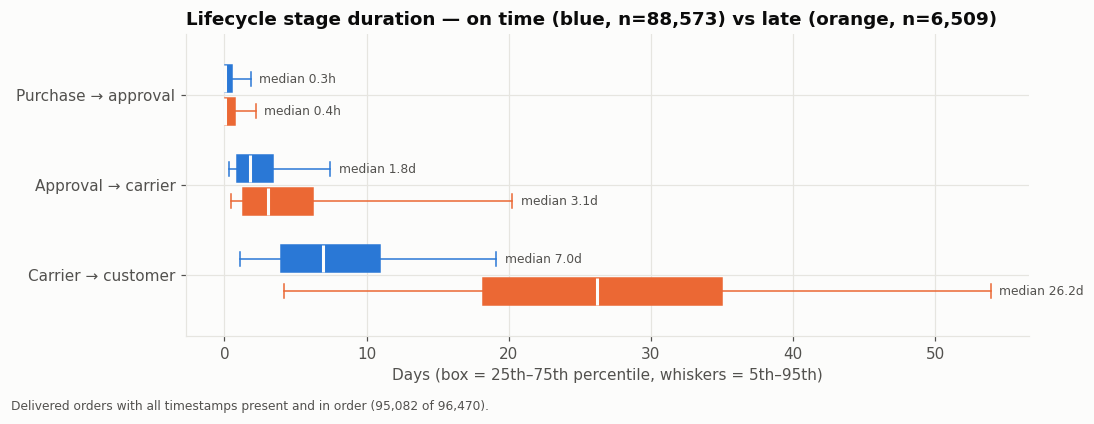

,hours_purchase_to_approval,days_approval_to_carrier,days_carrier_to_customer,days_purchase_to_estimate
is_late,,,,
on time,0.334,1.792,6.956,23.273
late,0.399,3.067,26.198,22.486


In [14]:
v = dl[dl.is_lifecycle_valid].copy()
stages = [("hours_purchase_to_approval", "Purchase → approval", 1/24),
          ("days_approval_to_carrier", "Approval → carrier", 1),
          ("days_carrier_to_customer", "Carrier → customer", 1)]
fig, ax = plt.subplots(figsize=(10, 3.8))
pos = np.arange(len(stages))
for i, (col, label, k) in enumerate(stages):
    for j, (flag, colr) in enumerate([(False, ON_TIME), (True, LATE)]):
        vals = v.loc[v.is_late == flag, col] * k
        bp = ax.boxplot(vals, positions=[i + (j - 0.5) * 0.36], widths=0.3, vert=False, showfliers=False,
                        patch_artist=True, whis=(5, 95), medianprops={"color": SURFACE, "lw": 2})
        for p in bp["boxes"]: p.set(facecolor=colr, edgecolor=colr)
        for el in bp["whiskers"] + bp["caps"]: el.set(color=colr)
        lbl = f"median {vals.median() * 24:.1f}h" if k != 1 else f"median {vals.median():.1f}d"
        ax.text(vals.quantile(0.95) + 0.6, i + (j - 0.5) * 0.36, lbl,
                va="center", fontsize=8, color=INK_2)
ax.set_yticks(pos, [s[1] for s in stages]); ax.invert_yaxis()
ax.set_xlabel("Days (box = 25th–75th percentile, whiskers = 5th–95th)")
ax.set_title(f"Lifecycle stage duration — on time (blue, n={(~v.is_late).sum():,}) vs late (orange, n={v.is_late.sum():,})")
fig.text(0.01, 0.005, f"Delivered orders with all timestamps present and in order ({len(v):,} of {len(dl):,}).",
         fontsize=8, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(FIG_DIR / "04_lifecycle_stages.png", dpi=150)
plt.show()

v.groupby("is_late")[["hours_purchase_to_approval", "days_approval_to_carrier", "days_carrier_to_customer",
                      "days_purchase_to_estimate"]].median().rename(index={False: "on time", True: "late"})

In [15]:
# Seller-controllable vs carrier stage: among late orders, how many were handed to the carrier after the seller deadline?
lt = v[v.is_late]
print(f"Late orders handed to carrier after the seller shipping deadline: {lt.is_carrier_handoff_late.mean():.1%} "
      f"(on-time orders: {v.loc[~v.is_late, 'is_carrier_handoff_late'].mean():.1%})")
extra_carrier = lt.days_carrier_to_customer.median() - v.loc[~v.is_late, 'days_carrier_to_customer'].median()
extra_seller  = lt.days_approval_to_carrier.median() - v.loc[~v.is_late, 'days_approval_to_carrier'].median()
print(f"Extra median days vs on-time: seller stage +{extra_seller:.1f}d, carrier stage +{extra_carrier:.1f}d")

Late orders handed to carrier after the seller shipping deadline: 27.9% (on-time orders: 7.8%)
Extra median days vs on-time: seller stage +1.3d, carrier stage +19.2d


**Reading:** for on-time orders, approval takes minutes, sellers hand over to the carrier in about 2 days, and carrier
transit takes about 7 days. **Late orders differ mostly in the carrier stage:** median transit is 26.2 days, 19.2 extra
days. The seller stage adds 1.3 days. Late orders are still about 3.5× more likely to have missed the seller's
shipping deadline (28% vs 8%), so seller dispatch is a secondary lever.

Outliers: stage medians are used throughout, and boxes are cut at the 5th–95th percentile.

In [16]:
outl = pd.DataFrame({
    "stage": [s[1] for s in stages] + ["Purchase → customer (total)"],
    "max_days": [v[c].max() * k for c, _, k in stages] + [dl.days_purchase_to_delivery.max()],
    "orders_over_60_days": [(v[c] * k > 60).sum() for c, _, k in stages] + [(dl.days_purchase_to_delivery > 60).sum()],
})
outl

,stage,max_days,orders_over_60_days
0,Purchase → approval,30.893,0
1,Approval → carrier,125.763,6
2,Carrier → customer,205.191,222
3,Purchase → customer (total),209.629,306


## 7. Summary of validated findings

| # | Finding | Evidence (sample size) |
|---|---|---|
| 1 | **6.8%** of delivered orders arrived after the estimated date (8.1% under the literal timestamp rule) | 6,534 / 96,470 orders |
| 2 | Lateness is **episodic**: Nov-2017 and Feb–Mar 2018 spikes; Feb–Mar 2018 affects every region | 3 months hold 21.6% of delivered orders but 48.3% of late orders |
| 3 | Late orders average **2.27 vs 4.29 stars**; the gap holds in every robustness subset | 6,381 late vs 89,443 on-time reviewed orders |
| 4 | 74.5% of late-order reviews are written **before delivery**; with these excluded the gap is −0.77 | 1,630 late orders reviewed after delivery |
| 5 | The extra time in late orders is mostly **carrier transit** (+19.2 days median), not seller handling (+1.3 days) | 95,082 orders with a valid lifecycle |
| 6 | Rankings must control for volume: a naive top-10 seller list is all sellers with <10 orders. 36 sellers with ≥100 orders sit above the chance band; category rates span only 4.3–8.1% | funnel plot, 2,970 sellers / 74 categories |

All findings are observational. They describe associations and should guide *what to test*, not prove causes.

In [17]:
con.close()